# CIFAR-10 embeddings: Simplex LDA + SIGRegNLL vs Softmax

Companion to `CIFAR10_Embeddings.ipynb`: keep its convolutional encoder,
nine-dimensional embeddings, fixed identity-covariance LDA head, Softmax baseline,
training settings, and two-panel PCA comparison. Replace the LDA model's NLL
objective with **SIGRegNLL**: generative NLL plus class-wise Gaussianity
regularization from [LeJEPA.pdf](LeJEPA.pdf), Section 4.2.3 and Algorithm 1.

- **Simplex LDA + SIGRegNLL:** fixed regular-simplex means, covariance
  $\Sigma=I_9$, and trainable class priors. Each class's embeddings are regularized
  toward $N(\mu_c,I_9)$ using the same fixed-center residual formulation as
  `Synthetic_SIGReg.ipynb`.
- **Softmax:** the same trainable linear head and cross-entropy objective as the
  reference notebook.

Both models start with identical encoder weights and use matched training
randomness and shuffled batches. PCA is fitted separately for each model on the
same unaugmented test images; panels have independent PCA axes and scales.
Test labels only color the points and measure accuracy.
The figure is saved to `plots/cifar10_sigregnll_vs_softmax_embeddings.png`.

Run all cells in order from `simplex-lda/` or its parent `LDA/`. Requires PyTorch,
torchvision, and Matplotlib; the first run may download CIFAR-10. Defaults remain
100 training epochs per model. `SIGREG_WEIGHT` controls the Gaussianity penalty;
zero recovers the original LDA NLL objective.


In [1]:
from pathlib import Path
import copy
import random
import sys

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Support kernels started in simplex-lda/ or its parent LDA/ directory.
project_dir = Path.cwd()
if not (project_dir / 'lda.py').is_file():
    project_dir = project_dir / 'simplex-lda'
if not (project_dir / 'lda.py').is_file():
    raise RuntimeError('Start the kernel in simplex-lda/ or its parent LDA/ directory.')
sys.path.insert(0, str(project_dir.resolve()))
from lda import SimplexLDAHead
from sigreg import SIGRegNLLLoss

SEED = 42
C, D = 10, 9
EPOCHS = 100
BATCH_SIZE = 256
NUM_WORKERS = 4  # Set to 0 if multiprocessing is unavailable.
LEARNING_RATE = 1e-3
SIGREG_WEIGHT = 1.0
SIGREG_NUM_SLICES = 256
SIGREG_SEED = 1729

def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pin_memory = device.type == 'cuda'
plot_dir = project_dir / 'plots'
plot_dir.mkdir(parents=True, exist_ok=True)
print('device =', device)


device = cuda


## CIFAR-10 data
Use all 50,000 training images with the reference augmentations and all 10,000 test images with deterministic evaluation transforms.

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_tfm = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_ds = datasets.CIFAR10(
    root=str(project_dir / 'data'), train=True, transform=train_tfm, download=True
)
test_ds = datasets.CIFAR10(
    root=str(project_dir / 'data'), train=False, transform=test_tfm, download=True
)
test_ld = DataLoader(
    test_ds, batch_size=1024, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
print(f'Train: {len(train_ds):,}; test / PCA: {len(test_ds):,}')

Train: 50,000; test / PCA: 10,000


## Shared encoder and classification heads

In [3]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(256, dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.proj(x)


class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D, covariance_type="identity")

    def forward(self, x):
        return self.head(self.encoder(x))


class DeepSoftmax(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = nn.Linear(D, C)

    def forward(self, x):
        return self.head(self.encoder(x))


seed_everything(SEED)
lda_model = DeepLDA(C, D).to(device)
softmax_model = DeepSoftmax(C, D).to(device)
softmax_model.encoder.load_state_dict(copy.deepcopy(lda_model.encoder.state_dict()))

# Identity covariance has no trainable scale, diagonal, or Cholesky parameters.
assert set(dict(lda_model.head.named_parameters())) == {'prior_logits'}
assert torch.equal(lda_model.head.covariance, torch.eye(D, device=device))

## Train with class-wise SIGRegNLL and evaluate

For identity covariance, the LDA score is
$s_c(z)=\log\pi_c-\frac12\lVert z-\mu_c\rVert^2$.
Retain the original generative NLL, $-\operatorname{mean}_i s_{y_i}(z_i)$,
**without applying `log_softmax`**, and add SIGReg:

\[
\mathcal L_{\mathrm{SIGRegNLL}}=\mathcal L_{\mathrm{NLL}}+
\lambda_G\sum_c\frac{n_c}{N}\mathrm{EP}_c,
\]
\[
\mathrm{EP}_c=\frac{n_c}{M}\sum_{m=1}^M
\operatorname{trapz}_{t_j}\left[
\left|\frac{1}{n_c}\sum_{i:y_i=c}
e^{it_j a_m^\top(z_i-\mu_c)}-e^{-t_j^2/2}\right|^2 e^{-t_j^2/2}
\right].
\]

`SIGRegNLLLoss` in `sigreg.py` wraps the tested `ClasswiseSIGReg` regularizer.
It uses $M=256$ random unit directions, resampled each minibatch with a private
generator, and 17 integration points on $[-5,5]$, following LeJEPA Algorithm 1.
Each class has a separate empirical characteristic function; subtract its
**fixed simplex center**, without empirical centering or whitening.
Frequency weighting across classes is the supervised adaptation. Classes with
fewer than two examples contribute zero, without renormalizing other weights.
The paper's $n_c$ multiplier is retained, making the strength batch-size
dependent. `SIGREG_WEIGHT=1.0` is a starting setting, not a tuned CIFAR-10 result.
Finite regularization encourages Gaussianity rather than guaranteeing it.

The Softmax baseline keeps `nn.CrossEntropyLoss()`. Training randomness and the
shuffled loader are reset for each model; private SIGReg sampling does not alter
augmentations or batch order. Test accuracy does not select epochs or weights.


In [4]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        logits = model(x.to(device, non_blocking=pin_memory))
        correct += (logits.argmax(1).cpu() == y).sum().item()
        total += y.size(0)
    return correct / total


def train_model(model, loss_fn, name):
    seed_everything(SEED)
    train_ld = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = loss_fn.to(device)
    history = {'loss': [], 'train_acc': [], 'test_acc': []}
    step = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = correct = total = 0
        for x, y in train_ld:
            x = x.to(device, non_blocking=pin_memory)
            y = y.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            if isinstance(loss_fn, SIGRegNLLLoss):
                embeddings = model.encoder(x)
                logits = model.head(embeddings)
                loss = loss_fn(logits, y, embeddings, model.head.mu, step=step)
            else:
                logits = model(x)
                loss = loss_fn(logits, y)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite {name} loss at epoch {epoch}, step {step}')
            loss.backward()
            optimizer.step()
            step += 1
            correct += (logits.detach().argmax(1) == y).sum().item()
            total += y.size(0)
            loss_sum += loss.item() * y.size(0)
        test_acc = evaluate(model, test_ld)
        history['loss'].append(loss_sum / total)
        history['train_acc'].append(correct / total)
        history['test_acc'].append(test_acc)
        print(f'[{name} {epoch:03d}] loss={loss_sum / total:.4f} '
              f'train acc={correct / total:.4f} | test acc={test_acc:.4f}')
    return history


In [5]:
sigreg_nll = SIGRegNLLLoss(
    gaussianity_weight=SIGREG_WEIGHT,
    num_slices=SIGREG_NUM_SLICES,
    seed=SIGREG_SEED,
)
lda_history = train_model(lda_model, sigreg_nll, 'Simplex LDA + SIGRegNLL, Sigma=I')
assert torch.equal(lda_model.head.covariance, torch.eye(D, device=device))


[Simplex LDA + SIGRegNLL, Sigma=I 001] loss=19.5921 train acc=0.4508 | test acc=0.4714
[Simplex LDA + SIGRegNLL, Sigma=I 002] loss=13.2011 train acc=0.6182 | test acc=0.6224
[Simplex LDA + SIGRegNLL, Sigma=I 003] loss=11.3731 train acc=0.6860 | test acc=0.6589
[Simplex LDA + SIGRegNLL, Sigma=I 004] loss=10.3744 train acc=0.7272 | test acc=0.6546
[Simplex LDA + SIGRegNLL, Sigma=I 005] loss=9.6976 train acc=0.7586 | test acc=0.7225
[Simplex LDA + SIGRegNLL, Sigma=I 006] loss=9.3486 train acc=0.7753 | test acc=0.7713
[Simplex LDA + SIGRegNLL, Sigma=I 007] loss=9.0189 train acc=0.7936 | test acc=0.7475
[Simplex LDA + SIGRegNLL, Sigma=I 008] loss=8.7984 train acc=0.8064 | test acc=0.7383
[Simplex LDA + SIGRegNLL, Sigma=I 009] loss=8.6185 train acc=0.8186 | test acc=0.7990
[Simplex LDA + SIGRegNLL, Sigma=I 010] loss=8.4404 train acc=0.8286 | test acc=0.7350
[Simplex LDA + SIGRegNLL, Sigma=I 011] loss=8.3403 train acc=0.8351 | test acc=0.8095
[Simplex LDA + SIGRegNLL, Sigma=I 012] loss=8.2554

In [6]:
softmax_history = train_model(softmax_model, nn.CrossEntropyLoss(), 'Softmax')

[Softmax 001] loss=1.3940 train acc=0.4927 | test acc=0.4987
[Softmax 002] loss=0.9319 train acc=0.6674 | test acc=0.6329
[Softmax 003] loss=0.7535 train acc=0.7348 | test acc=0.6017
[Softmax 004] loss=0.6399 train acc=0.7761 | test acc=0.7381
[Softmax 005] loss=0.5674 train acc=0.8053 | test acc=0.7753
[Softmax 006] loss=0.5154 train acc=0.8205 | test acc=0.7490
[Softmax 007] loss=0.4710 train acc=0.8363 | test acc=0.8105
[Softmax 008] loss=0.4336 train acc=0.8515 | test acc=0.7806
[Softmax 009] loss=0.4006 train acc=0.8618 | test acc=0.7612
[Softmax 010] loss=0.3803 train acc=0.8686 | test acc=0.8232
[Softmax 011] loss=0.3493 train acc=0.8783 | test acc=0.8300
[Softmax 012] loss=0.3310 train acc=0.8859 | test acc=0.8290
[Softmax 013] loss=0.3159 train acc=0.8901 | test acc=0.8264
[Softmax 014] loss=0.2948 train acc=0.8973 | test acc=0.8123
[Softmax 015] loss=0.2828 train acc=0.9031 | test acc=0.8363
[Softmax 016] loss=0.2671 train acc=0.9063 | test acc=0.8668
[Softmax 017] loss=0.255

## PCA of encoder embeddings

Collect both models' embeddings in a single pass over the test loader, ensuring
identical images and label order. Center each embedding matrix and compute exact
PCA using its SVD. No feature standardization or whitening is applied. The axis
labels show the fraction of total embedding variance explained by each component.
PCA visualizes only two directions of the nine-dimensional embeddings; it does
not by itself establish class-wise Gaussianity. The training penalty operates
on the full nine-dimensional embeddings.


In [7]:
@torch.no_grad()
def collect_embeddings(lda_model, softmax_model, loader):
    lda_model.eval()
    softmax_model.eval()
    lda_embeddings, softmax_embeddings, labels = [], [], []
    for x, y in loader:
        x = x.to(device, non_blocking=pin_memory)
        lda_embeddings.append(lda_model.encoder(x).cpu())
        softmax_embeddings.append(softmax_model.encoder(x).cpu())
        labels.append(y.cpu())
    return (torch.cat(lda_embeddings), torch.cat(softmax_embeddings),
            torch.cat(labels))


def project_pca(z):
    z_centered = z.double() - z.double().mean(dim=0, keepdim=True)
    _, singular_values, vh = torch.linalg.svd(z_centered, full_matrices=False)
    projected = z_centered @ vh[:2].T
    variances = singular_values.square()
    explained = variances[:2] / variances.sum().clamp_min(torch.finfo(z_centered.dtype).eps)
    return projected.numpy(), explained.numpy()


lda_z, softmax_z, labels = collect_embeddings(lda_model, softmax_model, test_ld)
lda_z2, lda_explained = project_pca(lda_z)
softmax_z2, softmax_explained = project_pca(softmax_z)
labels = labels.numpy()
print(f'PCA uses {len(labels):,} matching test images per model.')

PCA uses 10,000 matching test images per model.


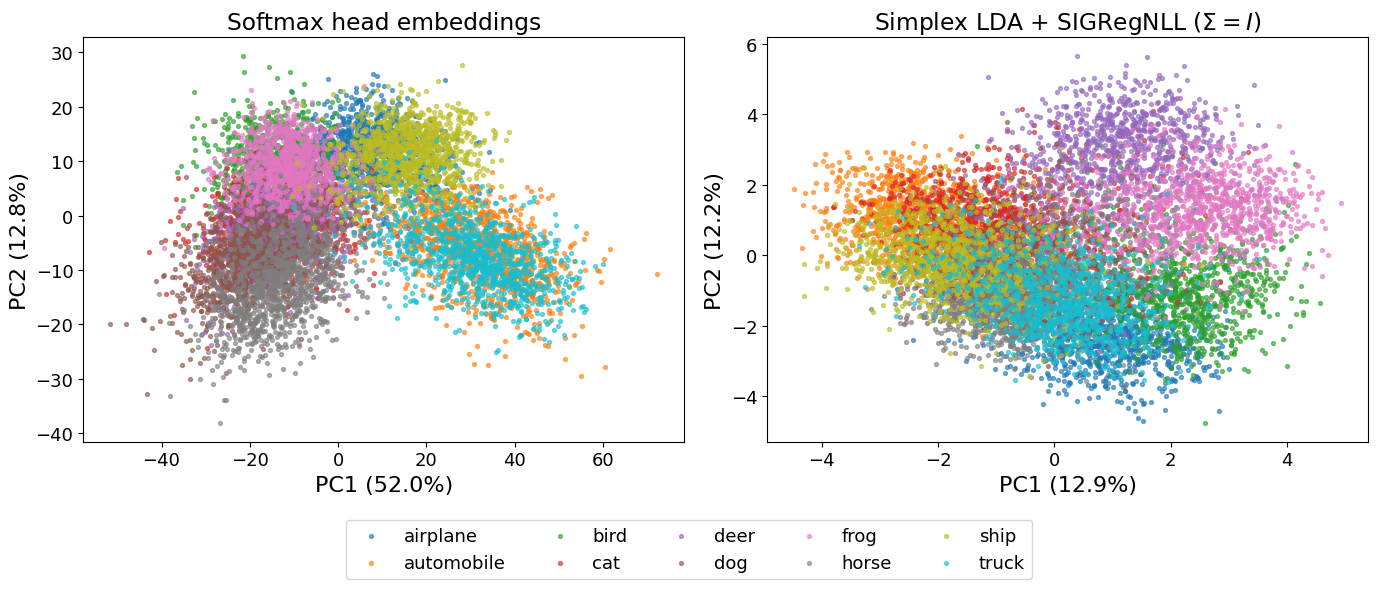

Saved: /home/zhenisbek/LDA/simplex-lda/plots/cifar10_sigregnll_vs_softmax_embeddings.png


In [8]:
plt.rcParams.update({
    'font.size': 14, 'axes.labelsize': 16, 'legend.fontsize': 13,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
})
palette = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plots = [
    (axes[0], softmax_z2, softmax_explained, 'Softmax head embeddings'),
    (axes[1], lda_z2, lda_explained, r'Simplex LDA + SIGRegNLL ($\Sigma = I$)'),
]
for ax, z2, explained, title in plots:
    for c, class_name in enumerate(test_ds.classes):
        mask = labels == c
        ax.scatter(z2[mask, 0], z2[mask, 1], s=8, alpha=0.6,
                   color=palette[c], label=class_name)
    ax.set_xlabel(f'PC1 ({explained[0]:.1%})')
    ax.set_ylabel(f'PC2 ({explained[1]:.1%})')
    ax.set_title(title)

handles, class_names = axes[0].get_legend_handles_labels()
fig.legend(handles, class_names, loc='lower center', ncol=5,
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.12, 1, 1))
output_path = plot_dir / 'cifar10_sigregnll_vs_softmax_embeddings.png'
fig.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()
print('Saved:', output_path.resolve())
